# 01. Preprocessing Dataset Foto BISINDO: Foto -> CSV -> NPZ

Notebook pertama dari dua. Hasilnya dipakai notebook **02_latih_ulang_model.ipynb**.

1. Lihat isi folder foto `images/train` (subfolder A-Z).
2. **Foto -> CSV**: MediaPipe membaca titik tangan dari setiap foto, lalu titiknya diubah menjadi 127 angka dengan normalisasi yang sama dengan server.
3. **Bersihkan data**: buang duplikat dan foto dua tangan yang hanya terdeteksi satu tangannya.
4. **Kelompokkan foto dan simpan NPZ**: foto yang nyaris kembar diberi nomor kelompok yang sama, lalu semuanya disimpan ke `.npz`.

Membaca 9.168 foto memakan waktu sekitar 15 menit. Bila CSV sudah ada dan ingin dilewati, ubah `BUAT_CSV = False`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# Notebook ada di ml/notebooks, sedangkan modul ada di ml/src.
ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd() / "ml"
SRC_DIR = ML_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from dataset.clean_dataset import clean_frame
from dataset.data_loader import FEATURE_COLUMNS
from dataset.extract_landmarks import DEFAULT_MODEL as MODEL_MEDIAPIPE
from training.retrain_from_photos import photo_groups

# ---------------- Pengaturan ----------------
FOTO_DIR = Path(r"C:\POLINEMA\SEMESTER 5\CobaPBL\bisindo\images\train")  # subfolder A-Z
CSV_PATH = ML_DIR / "data" / "processed" / "landmarks_train.csv"  # hasil: satu baris per foto
NPZ_PATH = ML_DIR / "data" / "processed" / "dataset_bisindo_landmarks_foto.npz"  # dipakai notebook 02
BUAT_CSV = True  # True = baca semua foto dan buat CSV dari awal (sekitar 15 menit); False = pakai CSV yang ada
BUANG_SATU_TANGAN = ['B', 'P']  # huruf dua tangan yang foto satu-tangannya dibuang
AMBANG_KEMBAR = 0.01    # foto dengan bentuk tangan sedekat ini dianggap satu kelompok

print("Folder foto:", FOTO_DIR, "| ada" if FOTO_DIR.exists() else "| TIDAK ADA")
print("CSV       :", CSV_PATH, "| akan dibuat dari foto" if BUAT_CSV or not CSV_PATH.exists() else "| memakai CSV yang ada")

Folder foto: C:\POLINEMA\SEMESTER 5\CobaPBL\bisindo\images\train | ada
CSV       : C:\POLINEMA\SEMESTER 5\bisindo\ml\data\processed\landmarks_train.csv | akan dibuat dari foto


## 1. Isi folder foto
Setiap huruf punya subfolder sendiri. Di bawah ini jumlah foto per huruf dan contoh satu foto per huruf. Perhatikan bahwa 16 huruf (A, B, D, F, G, H, K, M, N, P, Q, S, T, W, X, Y) dibentuk dengan **dua tangan**.

Total foto: 9168 di 26 folder huruf


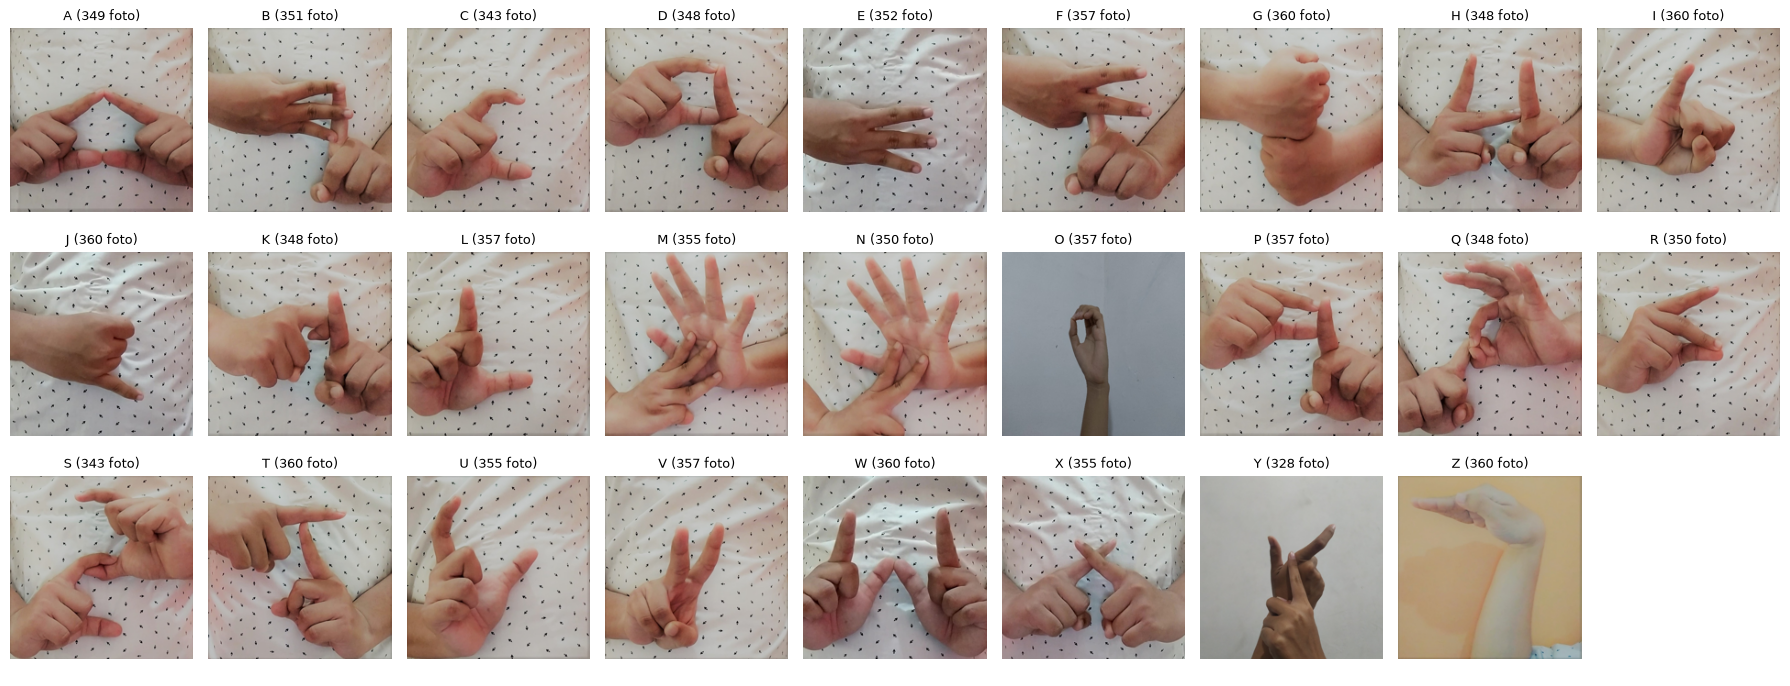

In [2]:
from PIL import Image

AKHIRAN_FOTO = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
foto_per_huruf = pd.Series({
    folder.name.upper(): sum(1 for f in folder.iterdir() if f.suffix.lower() in AKHIRAN_FOTO)
    for folder in sorted(FOTO_DIR.iterdir()) if folder.is_dir()
})
print(f"Total foto: {foto_per_huruf.sum()} di {len(foto_per_huruf)} folder huruf")

fig, axes = plt.subplots(3, 9, figsize=(18, 7))
for ax in axes.ravel():
    ax.axis("off")
for ax, huruf in zip(axes.ravel(), foto_per_huruf.index):
    berkas = sorted(f for f in (FOTO_DIR / huruf).iterdir() if f.suffix.lower() in AKHIRAN_FOTO)
    asli = [f for f in berkas if not f.name.startswith("augmented")] or berkas
    ax.imshow(Image.open(asli[0]).convert("RGB").resize((200, 200)))
    ax.set_title(f"{huruf} ({foto_per_huruf[huruf]} foto)", fontsize=9)
plt.tight_layout(); plt.show()

## 2. Foto -> CSV dengan MediaPipe
Bagian ini membuat CSV dari nol. Langkahnya:

1. Siapkan detektor MediaPipe Hand Landmarker (model yang sama dengan aplikasi Android, `hand_landmarker.task`).
2. Coba pada satu foto dan gambar titik-titiknya, supaya terlihat apa yang dibaca MediaPipe.
3. Ubah titik menjadi 127 angka dengan normalisasi yang **persis sama dengan server**.
4. Ulangi untuk semua foto, lalu simpan ke CSV.

### 2a. Siapkan detektor MediaPipe
`num_hands=2` karena 16 huruf memakai dua tangan. Mode `IMAGE` dipakai untuk foto diam.

In [3]:
import mediapipe as mp
from mediapipe.tasks.python import BaseOptions, vision

opsi = vision.HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=str(MODEL_MEDIAPIPE)),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.5,
)
detektor = vision.HandLandmarker.create_from_options(opsi)


def deteksi_tangan(jalur_foto):
    """Kembalikan daftar tangan; tiap tangan berupa array (21, 3) koordinat gambar 0-1."""
    hasil = detektor.detect(mp.Image.create_from_file(str(jalur_foto)))
    return [np.array([[t.x, t.y, t.z] for t in tangan]) for tangan in hasil.hand_landmarks]


print("Model MediaPipe:", MODEL_MEDIAPIPE)

Model MediaPipe: C:\POLINEMA\SEMESTER 5\bisindo\mobile\android\app\src\main\assets\hand_landmarker.task


### 2b. Coba pada satu foto
Titik biru adalah tangan pertama, titik oranye tangan kedua. Koordinat x dan y masih dalam satuan gambar (0 sampai 1).

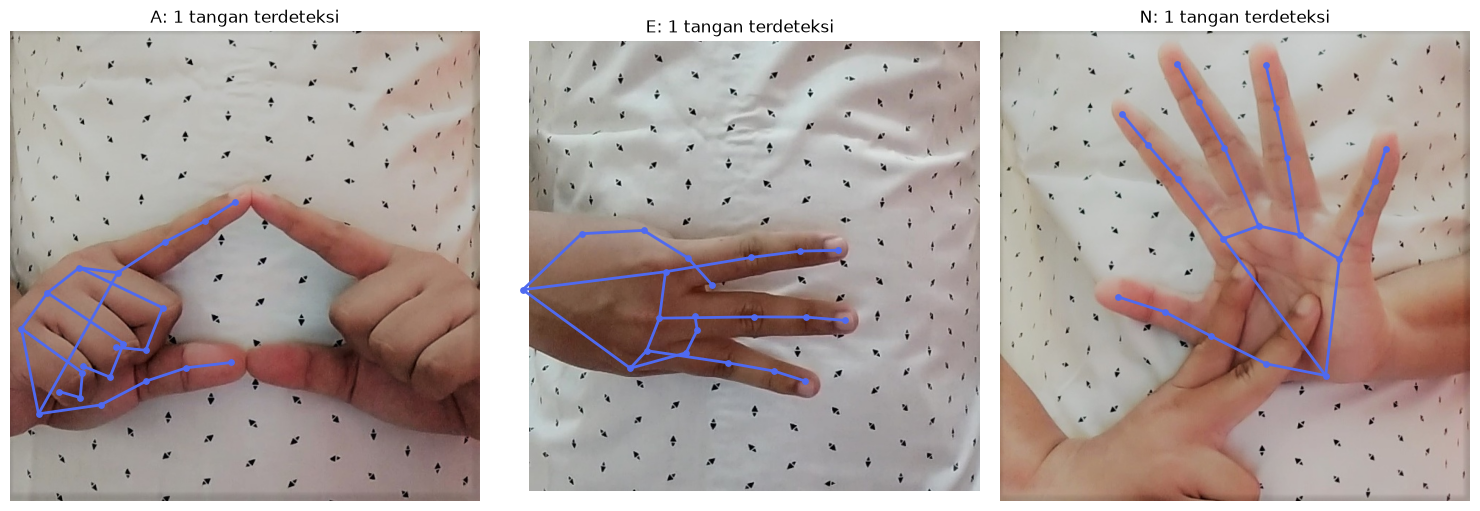

In [4]:
RANGKA = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
          (9,13),(13,14),(14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]
WARNA = ["#4F6AF0", "#F5A524"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, huruf in zip(axes, ["A", "E", "N"]):
    berkas = sorted(f for f in (FOTO_DIR / huruf).iterdir()
                    if f.suffix.lower() in AKHIRAN_FOTO and not f.name.startswith("augmented"))
    foto = berkas[0]
    gambar = Image.open(foto).convert("RGB")
    tangan = deteksi_tangan(foto)
    ax.imshow(gambar)
    for urutan, titik in enumerate(tangan):
        px, py = titik[:, 0] * gambar.width, titik[:, 1] * gambar.height
        for a, b in RANGKA:
            ax.plot([px[a], px[b]], [py[a], py[b]], color=WARNA[urutan], lw=2)
        ax.scatter(px, py, color=WARNA[urutan], s=15, zorder=3)
    ax.set_title(f"{huruf}: {len(tangan)} tangan terdeteksi"); ax.axis("off")
plt.tight_layout(); plt.show()

### 2c. Titik -> 127 angka
Supaya posisi dan ukuran tangan di foto tidak berpengaruh:

- **Urutan tangan**: tangan dengan pergelangan paling kiri di gambar menjadi tangan 1.
- **Geser**: semua titik dikurangi posisi pergelangan tangan 1 (titik 0), jadi pergelangan menjadi (0, 0, 0).
- **Skala**: semua titik dibagi panjang telapak tangan 1 (jarak pergelangan ke pangkal jari tengah, titik 9), jadi jarak itu selalu 1.
- Tangan 2 memakai acuan yang sama, sehingga posisi kedua tangan terhadap satu sama lain tetap tersimpan. Bila hanya satu tangan, 63 angka tangan 2 diisi nol.

Server (`web/app/api/services.py`) melakukan langkah yang sama pada titik yang dikirim HP, jadi data latih dan data dari HP berada di satuan yang sama.

In [5]:
def titik_ke_baris(tangan, huruf, nama_berkas):
    """Ubah tangan hasil deteksi menjadi satu baris CSV (127 fitur + keterangan)."""
    tangan = sorted(tangan, key=lambda t: t[0, 0])[:2]           # urutkan dari pergelangan paling kiri
    pergelangan = tangan[0][0]
    tangan1 = tangan[0] - pergelangan                             # geser
    tangan2 = tangan[1] - pergelangan if len(tangan) == 2 else np.zeros((21, 3))
    skala = np.linalg.norm(tangan1[9])                            # panjang telapak tangan 1
    if not np.isfinite(skala) or skala < 1e-6:
        return None                                               # tangan terlalu kecil
    tangan1, tangan2 = tangan1 / skala, tangan2 / skala

    baris = {"label": huruf, "label_idx": ord(huruf) - ord("A"), "filename": nama_berkas,
             "num_hands": len(tangan), "is_flip": 0}
    baris.update(zip(FEATURE_COLUMNS[:63], tangan1.ravel()))
    baris.update(zip(FEATURE_COLUMNS[63:126], tangan2.ravel()))
    baris["is_two_handed"] = int(len(tangan) == 2)
    return baris


contoh = titik_ke_baris(deteksi_tangan(foto), "N", foto.name)
print("Contoh baris untuk", foto.name)
print("  pergelangan tangan 1 :", [round(contoh[k], 3) for k in FEATURE_COLUMNS[0:3]])
print("  pangkal jari tengah  :", [round(contoh[k], 3) for k in FEATURE_COLUMNS[27:30]],
      "-> panjangnya", round(float(np.linalg.norm([contoh[k] for k in FEATURE_COLUMNS[27:30]])), 3))
print("  dua tangan           :", contoh["is_two_handed"])
print("  jumlah fitur         :", len(FEATURE_COLUMNS))

Contoh baris untuk body dot (1).jpg
  pergelangan tangan 1 : [np.float64(0.0), np.float64(0.0), np.float64(0.0)]
  pangkal jari tengah  : [np.float64(-0.384), np.float64(-0.857), np.float64(-0.345)] -> panjangnya 1.0
  dua tangan           : 0
  jumlah fitur         : 127


### 2d. Baca semua foto dan simpan ke CSV
Setiap foto dibaca satu kali. Foto yang tangannya tidak terdeteksi dilewati dan dicatat. Versi cermin tidak dibuat, jadi satu foto menjadi satu baris.

In [6]:
import time

if BUAT_CSV or not CSV_PATH.exists():
    semua_baris, tanpa_tangan = [], {}
    mulai = time.time()
    for huruf in foto_per_huruf.index:
        berkas = sorted(f for f in (FOTO_DIR / huruf).iterdir() if f.suffix.lower() in AKHIRAN_FOTO)
        gagal = 0
        for foto in berkas:
            tangan = deteksi_tangan(foto)
            baris = titik_ke_baris(tangan, huruf, foto.name) if tangan else None
            if baris is None:
                gagal += 1
            else:
                semua_baris.append(baris)
        tanpa_tangan[huruf] = gagal
        print(f"{huruf}: {len(berkas) - gagal:>3} dari {len(berkas)} foto terbaca "
              f"| total {len(semua_baris):>5} baris | {time.time() - mulai:5.0f} detik")

    mentah = pd.DataFrame(semua_baris, columns=["label", "label_idx", "filename", "num_hands", "is_flip",
                                                *FEATURE_COLUMNS])
    CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
    mentah.to_csv(CSV_PATH, index=False)
    print(f"\nCSV disimpan: {CSV_PATH} ({len(mentah)} baris)")
else:
    mentah = pd.read_csv(CSV_PATH)
    print(f"Memakai CSV yang sudah ada: {CSV_PATH} ({len(mentah)} baris)")

detektor.close()

terbaca = mentah.groupby("label").size().reindex(foto_per_huruf.index, fill_value=0)
ringkas = pd.DataFrame({"Foto": foto_per_huruf, "Tangan terdeteksi": terbaca,
                        "Tidak terdeteksi": foto_per_huruf - terbaca})
ringkas["% terdeteksi"] = (100 * ringkas["Tangan terdeteksi"] / ringkas["Foto"]).round(1)
print(f"Terdeteksi {terbaca.sum()} dari {foto_per_huruf.sum()} foto "
      f"({100 * terbaca.sum() / foto_per_huruf.sum():.1f}%)")
display(ringkas.T)
display(mentah.head(3))

A: 202 dari 349 foto terbaca | total   202 baris |    15 detik


B: 264 dari 351 foto terbaca | total   466 baris |    29 detik


C: 249 dari 343 foto terbaca | total   715 baris |    41 detik


D: 290 dari 348 foto terbaca | total  1005 baris |    58 detik


E: 279 dari 352 foto terbaca | total  1284 baris |    71 detik


F: 256 dari 357 foto terbaca | total  1540 baris |    86 detik


... (19 outputs left out)

Z: 262 dari 360 foto terbaca | total  7244 baris |   390 detik



CSV disimpan: C:\POLINEMA\SEMESTER 5\bisindo\ml\data\processed\landmarks_train.csv (7244 baris)
Terdeteksi 7244 dari 9168 foto (79.0%)


,A,B,C,D,E,F,G,H,I,J,...,Q,R,S,T,U,V,W,X,Y,Z
Foto,349.0,351.0,343.0,348.0,352.0,357.0,360.0,348.0,360.0,360.0,...,348.0,350.0,343.0,360.0,355.0,357.0,360.0,355.0,328.0,360.0
Tangan terdeteksi,202.0,264.0,249.0,290.0,279.0,256.0,271.0,260.0,307.0,300.0,...,255.0,306.0,284.0,267.0,281.0,297.0,269.0,290.0,179.0,262.0
Tidak terdeteksi,147.0,87.0,94.0,58.0,73.0,101.0,89.0,88.0,53.0,60.0,...,93.0,44.0,59.0,93.0,74.0,60.0,91.0,65.0,149.0,98.0
% terdeteksi,57.9,75.2,72.6,83.3,79.3,71.7,75.3,74.7,85.3,83.3,...,73.3,87.4,82.8,74.2,79.2,83.2,74.7,81.7,54.6,72.8


,label,label_idx,filename,num_hands,is_flip,h1_pt0_x,h1_pt0_y,h1_pt0_z,h1_pt1_x,h1_pt1_y,...,h2_pt18_x,h2_pt18_y,h2_pt18_z,h2_pt19_x,h2_pt19_y,h2_pt19_z,h2_pt20_x,h2_pt20_y,h2_pt20_z,is_two_handed
0,A,0,augmented_image_10.jpg,2,0,0.0,0.0,0.0,0.245496,-0.073111,...,1.927919,-1.660584,-0.213076,1.952719,-1.432863,-0.169712,1.959034,-1.269097,-0.108502,1
1,A,0,augmented_image_100.jpg,2,0,0.0,0.0,0.0,0.311346,0.030237,...,3.062486,-0.487912,-0.502795,2.982499,-0.291536,-0.470536,2.903052,-0.219729,-0.418562,1
2,A,0,augmented_image_11.jpg,2,0,0.0,0.0,0.0,0.338923,-0.063609,...,2.064733,-1.020051,-0.312355,2.062807,-0.731346,-0.327759,2.064429,-0.520041,-0.278915,1


## 3. Bersihkan data
Tiap baris berisi 127 angka: 21 titik tangan 1, 21 titik tangan 2 (masing-masing x, y, z), dan penanda dua tangan. Data yang dipakai adalah versi **tanpa cermin** (satu baris per foto). Banyak foto menghasilkan landmark yang sama persis, jadi duplikatnya dibuang dulu.

Selain itu, untuk huruf B dan P dibuang foto yang hanya terdeteksi **satu tangan**. B dan P dibentuk dengan dua tangan; kalau MediaPipe hanya menangkap satu tangan, separuh B mirip E dan separuh P mirip D, sehingga E dan D sering salah terbaca di HP.

Baris mentah : 7244
Dibuang      : {'nilai_tidak_terhingga': 0, 'penanda_dua_tangan': 0, 'normalisasi_tidak_sesuai': 0, 'duplikat_landmark': 1136}
Baris bersih : 6108
Dibuang (satu tangan dari huruf BP): 319
Baris dipakai: 5789


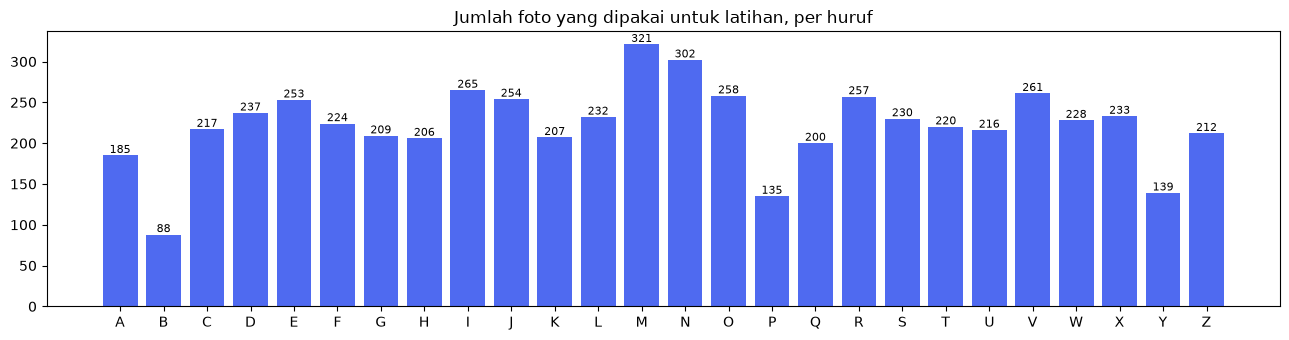

In [7]:
frame, dibuang = clean_frame(mentah)
print(f"Baris mentah : {len(mentah)}")
print(f"Dibuang      : {dibuang}")
print(f"Baris bersih : {len(frame)}")

# Huruf dua tangan yang hanya terdeteksi satu tangannya. Separuh huruf B mirip E,
# separuh huruf P mirip D, jadi baris seperti ini membuat model salah belajar.
separuh = frame["label"].isin(BUANG_SATU_TANGAN) & (frame["is_two_handed"] < 0.5)
frame = frame.loc[~separuh].reset_index(drop=True)
print(f"Dibuang (satu tangan dari huruf {''.join(BUANG_SATU_TANGAN)}): {int(separuh.sum())}")
print(f"Baris dipakai: {len(frame)}")

per_huruf = frame[frame["is_flip"] == 0].groupby("label").size()
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(per_huruf.index, per_huruf.values, color="#4F6AF0")
for x, v in zip(per_huruf.index, per_huruf.values):
    ax.text(x, v + 3, str(v), ha="center", fontsize=8)
ax.set_title("Jumlah foto yang dipakai untuk latihan, per huruf")
plt.tight_layout(); plt.show()

## 4. Kelompokkan foto dan simpan NPZ
Dataset berisi banyak jepretan beruntun dan hasil augmentasi gambar. Kalau nanti data dibagi acak per baris, foto yang nyaris kembar bisa masuk ke data latih **dan** data uji, sehingga akurasi tampak lebih tinggi dari kenyataan.

Karena itu setiap foto diberi nomor kelompok: foto yang bentuk tangannya nyaris sama (selisih rata-rata jarak antar titik di bawah `AMBANG_KEMBAR`) masuk kelompok yang sama. Notebook 02 memakai nomor ini supaya satu kelompok selalu berada di sisi yang sama (latih atau uji).

NPZ memakai kunci yang sama dengan notebook perbandingan 6 algoritma (`X`, `labels`, `label_indices`, `is_two_handed`, `feature_names`), ditambah `groups`.

In [8]:
features = frame[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
labels = frame["label"].astype(str).to_numpy()
groups = photo_groups(frame, AMBANG_KEMBAR)

kelompok = pd.DataFrame({"label": labels, "group": groups})
ringkas_kelompok = pd.DataFrame({
    "Foto": kelompok.groupby("label").size(),
    "Kelompok": kelompok.groupby("label")["group"].nunique(),
    "Kelompok terbesar": kelompok.groupby(["label", "group"]).size().groupby("label").max(),
})
print(f"Total: {len(features)} foto dalam {len(np.unique(groups))} kelompok")
display(ringkas_kelompok.T)

np.savez_compressed(
    NPZ_PATH, X=features, labels=labels.astype(object),
    label_indices=np.array([ord(h) - ord("A") for h in labels]),
    is_two_handed=features[:, -1], feature_names=np.array(FEATURE_COLUMNS), groups=groups,
)
cek = np.load(NPZ_PATH, allow_pickle=True)
print(f"NPZ disimpan: {NPZ_PATH}")
for kunci in cek.files:
    print(f"  {kunci:<14} {cek[kunci].shape}")

Total: 5789 foto dalam 2826 kelompok


label,A,B,C,D,E,F,G,H,I,J,...,Q,R,S,T,U,V,W,X,Y,Z
Foto,185,88,217,237,253,224,209,206,265,254,...,200,257,230,220,216,261,228,233,139,212
Kelompok,125,84,88,100,201,107,151,94,105,152,...,95,108,105,104,75,102,97,104,115,114
Kelompok terbesar,11,2,68,52,7,47,12,48,95,32,...,46,59,43,54,75,144,43,66,22,51


NPZ disimpan: C:\POLINEMA\SEMESTER 5\bisindo\ml\data\processed\dataset_bisindo_landmarks_foto.npz
  X              (5789, 127)
  labels         (5789,)
  label_indices  (5789,)
  is_two_handed  (5789,)
  feature_names  (127,)
  groups         (5789,)


Selesai. Lanjutkan ke **02_latih_ulang_model.ipynb** untuk melatih dan menilai model dari NPZ ini.